<p style="text-align:center"><img src="images/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Web Apps for Geospatial Data: Streamlit, Panel and Solara

A web map (Notebook 08_04) shows data; an API (08_06) answers programs. A **web app** lets people
*explore*: pick a district, switch the variable on the map, read the numbers and charts that
follow. Python now has frameworks that build such apps without writing HTML or JavaScript. This
notebook builds the same app, a **Bangladesh district explorer**, in the three most used ones:

- **Streamlit**: a script that reruns from top to bottom on every interaction;
- **Panel** (HoloViz): widgets and outputs linked by explicit dependencies, served by Bokeh;
- **Solara**: React-style components with reactive state, built on ipywidgets.

The app shows a choropleth of poverty, population density, rice production or vegetation trends;
headline numbers for the selected district; and 25 years of MODIS NDVI for it, as a time series
and as a monthly calendar. All three apps share one plain-Python module for data and figures,
which is the most important design decision in this notebook.



### Learning objectives

1. Structure an app as a thin user interface over a tested logic module.
2. Prepare app data in advance, so the app loads kilobytes rather than gigabytes.
3. Build the same app in Streamlit, Panel and Solara, and test each one without a browser.
4. Measure each framework's execution model: what is recomputed when the user changes one control.
5. Run the apps as servers, and measure start-up time and memory.
6. Choose a framework and a hosting option for a given audience.



### Data

| Data | Source |
|---|---|
| District poverty, population and rice production | `Data/00_shared/data_web_cloud_gis/08_03_outputs/districts.gpkg` (Notebook 08_03) |
| MODIS 16-day NDVI, 1 km, Bangladesh, 2000-2024 (572 images) | `Data/00_shared/data_remote_sensing/MODIS/MODIS_NDVI_BD/` |
| The three apps and their shared module | `apps/bd_dashboard.py`, `apps/bd_streamlit.py`, `apps/bd_panel.py`, `apps/bd_solara.py` next to this notebook |

Run Notebook 08_03 first. Install the frameworks with
`pip install streamlit streamlit-folium panel solara plotly folium`.



### Contents

1. Setup
2. Three ways to build a Python web app
3. Design: a logic module and thin user interfaces
4. Preparing data for an app
5. The Streamlit app
6. The Panel app
7. The Solara app
8. Execution models compared
9. Running the apps as servers
10. Sharing and choosing
11. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `panel`, `psutil`, `solara`, which no GeoLattice option installs: `pip install panel psutil solara`.

In [1]:
# Imports and paths for Streamlit, Panel, and Solara dashboard apps
%matplotlib inline
import importlib
import inspect
import socket
import subprocess
import sys
import time
import warnings
from pathlib import Path

import os
warnings.filterwarnings("ignore")
os.environ["STREAMLIT_LOGGER_LEVEL"] = "error"          # quiet the "bare mode" messages of headless tests

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import rasterio
from rasterio.features import geometry_mask
from shapely.geometry import mapping
import httpx
import psutil
import matplotlib.pyplot as plt
from IPython.display import Code, IFrame, display

import logging
import streamlit
logging.getLogger("streamlit.runtime.scriptrunner_utils.script_run_context").setLevel(logging.ERROR)
import panel as pn
import solara

import geolattice

# Data folders, app scripts, and output directory
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
WEB = DATA / "00_shared" / "data_web_cloud_gis"
MODIS = DATA / "00_shared" / "data_remote_sensing" / "MODIS" / "MODIS_NDVI_BD"
APPS = Path("apps").resolve()
OUT = WEB / "08_07_outputs"
OUT.mkdir(parents=True, exist_ok=True)
if not (WEB / "08_03_outputs" / "districts.gpkg").exists():
    raise FileNotFoundError("districts.gpkg is missing: run Notebook 08_03 first")
sys.path.insert(0, str(APPS))
print("geolattice", geolattice.__version__, "| Streamlit", streamlit.__version__, "| Panel", pn.__version__,
      "| Solara", solara.__version__)
print("apps:", sorted(p.name for p in APPS.glob("*.py")))

geolattice 0.3.11 | Streamlit 1.66.0 | Panel 1.9.4 | Solara 1.64.0
apps: ['bd_dashboard.py', 'bd_panel.py', 'bd_solara.py', 'bd_streamlit.py']


## Three ways to build a Python web app

| | **Streamlit** | **Panel** | **Solara** |
|---|---|---|---|
| Programming model | A script; every interaction reruns it from the top | Widgets, panes and functions linked by declared dependencies | Components (functions) that re-render when reactive state they read changes |
| Where state lives | `st.session_state`, widget keys | Widget and `param` values | `solara.reactive` variables and hooks (`use_state`, `use_memo`) |
| Avoiding repeated work | `st.cache_data` / `st.cache_resource` | Only dependent functions run; `pn.cache` | `use_memo`, and only components that read changed state re-render |
| Runs on | Tornado server, own protocol | Bokeh server; also in Jupyter, or compiled to WebAssembly (Pyodide) | Starlette server; also in Jupyter (ipywidgets) |
| Maps | `streamlit-folium`, pydeck, leafmap | Folium, ipyleaflet, deck.gl, HoloViews/GeoViews, lonboard | ipyleaflet, leafmap, Folium (HTML), lonboard |
| Strength | Fastest start; huge community; Community Cloud hosting | Big data and linked plots (HoloViz); notebook to app | Scales to complex, multi-page apps with React-like structure |

All three serve a page whose widgets talk to a Python process over a WebSocket: each browser tab is
a **session** on the server, and the Python code runs on the server, not in the browser.

## Design: a logic module and thin user interfaces

The data loading, the map and the charts live in `apps/bd_dashboard.py`, a module with no web
framework in it. Each app only arranges widgets and calls these functions. This makes the logic
testable with plain Python, lets the three apps share it, and keeps a later change of framework
cheap. The module also counts its function calls (`CALLS`), which Section 8 uses.

In [2]:
# Inspect the shared bd_dashboard logic module (public functions and map variables)
import bd_dashboard as bd
print(f"{len(Path(bd.__file__).read_text().splitlines())} lines in bd_dashboard.py; public functions:")
for name, f in inspect.getmembers(bd, inspect.isfunction):
    if not name.startswith("_") and f.__module__ == "bd_dashboard":
        print(f"  {name}{inspect.signature(f)}")
print("map variables:", list(bd.VARIABLES))

133 lines in bd_dashboard.py; public functions:
  choropleth(gdf: 'gpd.GeoDataFrame', variable: 'str', highlight: 'Optional[str]' = None, height: 'int' = 480) -> 'folium.Map'
  district_card(gdf: 'gpd.GeoDataFrame', district: 'str') -> 'dict'
  district_list(gdf: 'gpd.GeoDataFrame', division: 'Optional[str]' = None) -> 'list[str]'
  load_districts() -> 'gpd.GeoDataFrame'
  load_ndvi() -> 'pd.DataFrame'
  ndvi_figure(ndvi: 'pd.DataFrame', district: 'str', height: 'int' = 330) -> 'go.Figure'
  seasonal_figure(ndvi: 'pd.DataFrame', district: 'str', height: 'int' = 280) -> 'go.Figure'
map variables: ['poverty_pct', 'density', 'rice_t_km2', 'ndvi_max_mean', 'ndvi_trend']


## Preparing data for an app

An app should open in a second. The raw inputs would take far longer: 572 NDVI images (368 MB in
memory) and district boundaries with a million vertices. Everything the app shows can be computed
in advance: the mean NDVI of each district on each date, the long-term mean and trend of each
district's annual NDVI peak, and boundaries simplified for display. The app then reads two small
Parquet files.

In [3]:
# Build district NDVI time series and trend stats; write compact Parquet for the apps
t0 = time.perf_counter()
# Load districts and the full MODIS NDVI stack into memory
districts = gpd.read_file(WEB / "08_03_outputs" / "districts.gpkg")
files = sorted(MODIS.glob("ndvi_*.tif"), key=lambda p: (int(p.stem.split("_")[1]), int(p.stem.split("_")[2])))
dates = pd.to_datetime([f"{p.stem.split('_')[1]}-{p.stem.split('_')[2]}" for p in files], format="%Y-%j")
with rasterio.open(files[0]) as src:
    crs, transform, shape = src.crs, src.transform, src.shape
cube = np.stack([rasterio.open(f).read(1) for f in files])                  # NDVI x 10,000; 0 = outside
raw_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
# Per-district mean NDVI series and Theil-Sen trend of annual peaks
years = np.arange(2001, 2025)
i, j = np.triu_indices(len(years), 1)
series, stats = [], []
for name, geom in zip(districts.district, districts.to_crs(crs).geometry):
    inside = geometry_mask([mapping(geom)], out_shape=shape, transform=transform, invert=True)
    v = cube[:, inside].astype("float32")
    v[v == 0] = np.nan
    mean = np.nanmean(v, axis=1) / 1e4
    series.append(pd.DataFrame({"district": name, "date": dates, "ndvi": mean.round(4)}))
    peak = pd.Series(mean, index=dates).groupby(lambda d: d.year).max().reindex(years).values
    stats.append({"district": name, "ndvi_max_mean": np.nanmean(peak),
                  "ndvi_trend": np.nanmedian((peak[j] - peak[i]) / (years[j] - years[i])) * 10})   # Theil-Sen, per decade
ndvi_long = pd.concat(series, ignore_index=True)
table = districts.merge(pd.DataFrame(stats), on="district")
table["density"] = table.population / table.area_km2
table["rice_t_km2"] = table.rice_t / table.area_km2
simple = gpd.GeoSeries(shapely.coverage_simplify(table.to_crs(32646).geometry.values, 500), crs=32646).to_crs(4326)
table = table.set_geometry(shapely.set_precision(simple.values, 1e-4)).set_crs(4326, allow_override=True)
table.to_parquet(OUT / "districts.parquet")
ndvi_long.to_parquet(OUT / "district_ndvi.parquet")
prep_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
# Time how long the prepared Parquet loads take in the app module
bd.load_districts(); bd.load_ndvi()
app_seconds = time.perf_counter() - t0
pd.DataFrame({"what": ["raw inputs (572 GeoTIFFs + boundaries)", "prepared app data (2 Parquet files)"],
              "size": [f"{cube.nbytes / 1e6:.0f} MB in memory, {districts.geometry.count_coordinates().sum():,} vertices",
                       f"{sum(p.stat().st_size for p in OUT.glob('*.parquet')) / 1e3:.0f} kB on disk, "
                       f"{table.geometry.count_coordinates().sum():,} vertices"],
              "load seconds": [round(raw_seconds, 2), round(app_seconds, 3)]}).assign(
    note=["", f"preparation took {prep_seconds:.1f} s, once"])

,what,size,load seconds,note
0,raw inputs (572 GeoTIFFs + boundaries),"368 MB in memory, 1,063,772 vertices",3.110,
1,prepared app data (2 Parquet files),"288 kB on disk, 16,559 vertices",0.027,"preparation took 2.1 s, once"


In [4]:
# Prepare compact app inputs (districts table and NDVI summaries)
show = table.drop(columns="geometry").set_index("district")[["division", "poverty_pct", "density", "rice_t_km2", "ndvi_max_mean", "ndvi_trend"]]
print("Largest and smallest NDVI trends (annual peak, per decade, 2001-2024):")
display(pd.concat([show.nlargest(4, "ndvi_trend"), show.nsmallest(4, "ndvi_trend")]).round(3))
print(f"Districts with a positive trend: {(show.ndvi_trend > 0).sum()} of {len(show)}; "
      f"correlation of trend with population density: {show.ndvi_trend.corr(show.density, method='spearman'):.2f} (Spearman)")

Largest and smallest NDVI trends (annual peak, per decade, 2001-2024):


,division,poverty_pct,density,rice_t_km2,ndvi_max_mean,ndvi_trend
district,,,,,,
Naogaon,Rajshahi,16.9,752.660,418.046,0.683,0.067
Natore,Rajshahi,35.0,895.095,254.712,0.639,0.067
Faridpur,Dhaka,36.3,935.793,155.812,0.629,0.067
Pabna,Rajshahi,31.5,1055.345,181.311,0.582,0.066
Bagerhat,Khulna,42.8,404.482,0.000,0.630,-0.013
Satkhira,Khulna,46.3,589.976,166.104,0.522,-0.005
Khagrachhari,Chittagong,25.5,214.664,41.641,0.840,0.001
Rangamati,Chittagong,20.2,104.588,11.252,0.815,0.001


Districts with a positive trend: 62 of 64; correlation of trend with population density: 0.03 (Spearman)


Preparation took 2.1 s, once. The app then loads 288 kB (two Parquet files) in 0.03 s, against
3.1 s and 368 MB for the raw rasters, and draws 16,559 vertices instead of 1.06 million.

The new trend variable is worth a look:

- Annual peak NDVI rose in **62 of the 64 districts** between 2001 and 2024. The largest gains,
  about +0.067 per decade, are in the north-west (Naogaon, Natore, Pabna) and in Faridpur.
- Only Bagerhat (−0.013) and Satkhira (−0.005) declined, both in the south-western coastal belt.
- The forested hill districts (Khagrachhari, Rangamati) were already at the top (mean peak about
  0.82-0.84) and barely changed.
- The trend is unrelated to population density (Spearman 0.03).

One data gap shows up as well: Bagerhat's rice production is 0 in the district table, which points
to a missing row in the rice data joined in Notebook 08_03 rather than a real value.

## The Streamlit app

A Streamlit app is a script. Widgets return their current values; the script then draws the page.
When the user changes a widget, Streamlit **reruns the whole script** with the new value.
`@st.cache_data` keeps the data loaders from running again.

In [5]:
# Show the Streamlit app source
display(Code(filename=str(APPS / "bd_streamlit.py"), language="python"))

"""
Bangladesh district explorer, Streamlit version (Notebook 08_07).

Run:  streamlit run bd_streamlit.py
"""

import streamlit as st
from streamlit_folium import st_folium

import bd_dashboard as bd

st.set_page_config(page_title="Bangladesh district explorer", page_icon="🌾", layout="wide")


@st.cache_data                     # read once per server process, shared by every session
def districts():
    return bd.load_districts()


@st.cache_data
def ndvi():
    return bd.load_ndvi()


gdf, nd = districts(), ndvi()

with st.sidebar:
    st.header("Select")
    division = st.selectbox("Division", ["All"] + sorted(gdf.division.unique()), key="division")
    names = bd.district_list(gdf, division)
    district = st.selectbox("District", names, index=names.index("Bogra") if "Bogra" in names else 0, key="district")
    variable = st.radio("Map variable", list(bd.VARIABLES), format_func=bd.VARIABLES.get, key="variable")
    st.caption("Data: BBS poverty and census tables, DAE rice statistics, MODIS NDVI 2000-2024 (Notebooks 08_03, 08_06).")

st.title("Bangladesh district explorer")
card = bd.district_card(gdf, district)
c1, c2, c3, c4 = st.columns(4)
c1.metric("Poverty", f"{card['poverty_pct']:.1f} %" if card["poverty_pct"] is not None else "n/a",
          f"rank {card['poverty_rank']} of 64" if card["poverty_rank"] else None, delta_color="off")
c2.metric("Population density", f"{card['density']:,.0f} per km²" if card["density"] else "n/a")
c3.metric("Rice 2018-19", f"{card['rice_kt']:,.0f} kt", f"rank {card['rice_rank']} of 64 per km²", delta_color="off")
c4.metric("NDVI trend", f"{card['ndvi_trend']:+.3f} / decade", f"rank {card['ndvi_trend_rank']} of 64", delta_color="off")

left, right = st.columns([1, 1])
with left:
    st_folium(bd.choropleth(gdf, variable, district), height=480, use_container_width=True, returned_objects=[])
with right:
    st.plotly_chart(bd.ndvi_figure(nd, district), width="stretch")
    st.plotly_chart(bd.seasonal_figure(nd, district), width="stretch")

Streamlit's `AppTest` runs the script headless, as a user session would, and lets a test change
widgets and read what the page shows. We count which functions of the logic module each
interaction runs.

In [6]:
# Drive Streamlit via AppTest: open app, pick district/map variable/division; record call counts
from streamlit.testing.v1 import AppTest

def take():
    "Return and reset the call counts of the logic module."
    c = dict(bd.CALLS); bd.CALLS.clear(); return c

counts = {}
bd.CALLS.clear()
at = AppTest.from_file(str(APPS / "bd_streamlit.py"), default_timeout=60)
steps = [("open the app", lambda: at.run()),
         ("choose district Dhaka", lambda: at.selectbox(key="district").select("Dhaka").run()),
         ("switch map to NDVI trend", lambda: at.radio(key="variable").set_value("ndvi_trend").run()),
         ("choose division Sylhet", lambda: at.selectbox(key="division").select("Sylhet").run())]
for label, action in steps:
    t0 = time.perf_counter(); action()
    counts[("Streamlit", label)] = {"ms": (time.perf_counter() - t0) * 1000, **take()}
print("errors:", list(at.exception))
print("metrics after the last step:", {m.label: m.value for m in at.metric})
print("district selected after choosing Sylhet:", at.selectbox(key="district").value)
pd.DataFrame(counts).T.fillna(0).round(0)

errors: []
metrics after the last step: {'Poverty': '25.2 %', 'Population density': '817 per km²', 'Rice 2018-19': '787 kt', 'NDVI trend': '+0.048 / decade'}
district selected after choosing Sylhet: Habiganj


ms  load_districts  load_ndvi  \
Streamlit open the app              708.0             1.0        1.0   
          choose district Dhaka     327.0             0.0        0.0   
          switch map to NDVI trend  198.0             0.0        0.0   
          choose division Sylhet    190.0             0.0        0.0   

                                    district_card  choropleth  ndvi_figure  \
Streamlit open the app                        1.0         1.0          1.0   
          choose district Dhaka               1.0         1.0          1.0   
          switch map to NDVI trend            1.0         1.0          1.0   
          choose division Sylhet              1.0         1.0          1.0   

                                    seasonal_figure  
Streamlit open the app                          1.0  
          choose district Dhaka                 1.0  
          switch map to NDVI trend              1.0  
          choose division Sylhet                1.0

The app ran without exceptions, and the headline numbers updated as a user would see them. After
the division was set to Sylhet, the district selector fell back to the first district of the
division, Habiganj (poverty 25.2%, NDVI trend +0.048 per decade).

The counts show the execution model:

- The data were loaded once (cached).
- **Every interaction rebuilt all four outputs:** the card, the map and both charts. Switching only
  the map variable redrew the two NDVI charts as well.
- Each rerun took 0.19-0.33 s in the test harness.

## The Panel app

Panel separates the parts: widgets, output panes and the functions that fill them. Each function
declares which widgets it depends on (`@pn.depends(..., watch=True)`), and Panel calls it only when
one of them changes. `build()` returns the template and the widgets, so a test can drive them.

In [7]:
# Show the Panel app source
display(Code(filename=str(APPS / "bd_panel.py"), language="python"))

"""
Bangladesh district explorer, Panel version (Notebook 08_07).

Run:  panel serve bd_panel.py
"""

import panel as pn

import bd_dashboard as bd

pn.extension("plotly", sizing_mode="stretch_width")


@pn.cache                          # read once per server process, shared by every session
def data():
    return bd.load_districts(), bd.load_ndvi()


def build():
    """Create the widgets, panes and template; return (template, widgets) so tests can drive them."""
    gdf, nd = data()
    division = pn.widgets.Select(name="Division", options=["All"] + sorted(gdf.division.unique()), value="All")
    district = pn.widgets.Select(name="District", options=bd.district_list(gdf), value="Bogra")
    variable = pn.widgets.RadioButtonGroup(name="Map variable", options={v: k for k, v in bd.VARIABLES.items()},
                                           value="poverty_pct", orientation="vertical", button_type="light")

    cards = pn.pane.Markdown()
    map_pane = pn.pane.plot.Folium(height=480)
    ts_pane = pn.pane.Plotly(height=330)
    season_pane = pn.pane.Plotly(height=280)

    # Each output is recomputed only when one of its own inputs changes.
    @pn.depends(division, watch=True)
    def _filter(div):
        names = bd.district_list(gdf, div)
        district.options = names
        if district.value not in names:
            district.value = names[0]

    @pn.depends(district, watch=True)
    def _district(name):
        c = bd.district_card(gdf, name)
        pov = f"{c['poverty_pct']:.1f} % (rank {c['poverty_rank']} of 64)" if c["poverty_pct"] is not None else "n/a"
        cards.object = (f"### {name}, {c['division']} division\n"
                        f"**Poverty** {pov} · **Density** {c['density']:,.0f} per km² · "
                        f"**Rice** {c['rice_kt']:,.0f} kt · **NDVI trend** {c['ndvi_trend']:+.3f} per decade")
        ts_pane.object = bd.ndvi_figure(nd, name)
        season_pane.object = bd.seasonal_figure(nd, name)

    @pn.depends(variable, district, watch=True)
    def _map(var, name):
        map_pane.object = bd.choropleth(gdf, var, name)

    _district(district.value)              # first render
    _map(variable.value, district.value)
    template = pn.template.FastListTemplate(
        title="Bangladesh district explorer",
        sidebar=[division, district, pn.pane.Markdown("**Map variable**"), variable,
                 pn.pane.Markdown("Data: BBS, DAE, MODIS NDVI 2000-2024 (Notebooks 08_03, 08_06).")],
        main=[cards, pn.Row(map_pane, pn.Column(ts_pane, season_pane))],
        accent="#2c7fb8")
    return template, {"division": division, "district": district, "variable": variable,
                      "cards": cards, "map": map_pane, "timeseries": ts_pane, "seasonal": season_pane}


if __name__.startswith("bokeh"):    # `panel serve` runs this file once per browser session
    build()[0].servable()

In [8]:
# Build the Panel app in-process and replay the same widget interactions
import bd_panel
take()
t0 = time.perf_counter()
template, w = bd_panel.build()
counts[("Panel", "open the app")] = {"ms": (time.perf_counter() - t0) * 1000, **take()}
for label, (widget, value) in {"choose district Dhaka": ("district", "Dhaka"),
                                "switch map to NDVI trend": ("variable", "ndvi_trend"),
                                "choose division Sylhet": ("division", "Sylhet")}.items():
    t0 = time.perf_counter(); w[widget].value = value
    counts[("Panel", label)] = {"ms": (time.perf_counter() - t0) * 1000, **take()}
print("district selected after choosing Sylhet:", w["district"].value)
print(w["cards"].object)
pd.DataFrame({k: v for k, v in counts.items() if k[0] == "Panel"}).T.fillna(0).round(0)

district selected after choosing Sylhet: Habiganj
### Habiganj, Sylhet division
**Poverty** 25.2 % (rank 48 of 64) · **Density** 817 per km² · **Rice** 787 kt · **NDVI trend** +0.048 per decade


ms  load_districts  load_ndvi  \
Panel open the app              106.0             1.0        1.0   
      choose district Dhaka      56.0             0.0        0.0   
      switch map to NDVI trend   40.0             0.0        0.0   
      choose division Sylhet    205.0             0.0        0.0   

                                district_card  ndvi_figure  seasonal_figure  \
Panel open the app                        1.0          1.0              1.0   
      choose district Dhaka               1.0          1.0              1.0   
      switch map to NDVI trend            0.0          0.0              0.0   
      choose division Sylhet              1.0          1.0              1.0   

                                choropleth  
Panel open the app                     1.0  
      choose district Dhaka            1.0  
      switch map to NDVI trend         1.0  
      choose division Sylhet           1.0

Panel rebuilt only what depended on the change:

- **District change:** the card, the two charts and the map (which outlines the district).
- **Map variable:** only the map (40 ms).
- **Division change:** updated the district list. That in turn changed the district, which
  triggered the district outputs once.

The same app also runs inside this notebook, because Panel objects display in Jupyter. The template
is for the server; the main area can be shown directly:

In [9]:
# Display a slice of the live Panel layout in the notebook
pn.extension("plotly")
pn.Column(w["cards"], pn.Row(w["district"], w["variable"]), w["timeseries"], width=900)

Column(width=900)
    [0] Markdown(str, sizing_mode='stretch_width')
    [1] Row(sizing_mode='stretch_width')
        [0] Select(label='District', name='District', options=['Habiganj', 'Maulvibazar'...], sizing_mode='stretch_width', value='Habiganj')
        [1] RadioButtonGroup(button_type='light', color='light', label='Map variable', name='Map variable', options={'Poverty (% of population...}, orientation='vertical', sizing_mode='stretch_width', value='ndvi_trend')
    [2] Plotly(Figure, height=330, sizing_mode='stretch_width')

## The Solara app

Solara builds the page from **components**, functions decorated with `@solara.component`. State is
held in `solara.reactive` variables; when one changes, the components that read it run again.
Inside a component, `use_memo` keeps an expensive result until one of its listed dependencies
changes, much as `pn.depends` does in Panel.

In [10]:
# Show the Solara app source
display(Code(filename=str(APPS / "bd_solara.py"), language="python"))

"""
Bangladesh district explorer, Solara version (Notebook 08_07).

Run:  solara run bd_solara.py
"""

import solara

import bd_dashboard as bd

GDF, NDVI = bd.load_districts(), bd.load_ndvi()     # module level: loaded once per server process

# Reactive state; Solara keeps a separate copy for every browser session.
division = solara.reactive("All")
district = solara.reactive("Bogra")
variable = solara.reactive("poverty_pct")


@solara.component
def Cards(name: str):
    c = solara.use_memo(lambda: bd.district_card(GDF, name), dependencies=[name])
    pov = f"{c['poverty_pct']:.1f} % (rank {c['poverty_rank']} of 64)" if c["poverty_pct"] is not None else "n/a"
    solara.Markdown(f"### {name}, {c['division']} division\n"
                    f"**Poverty** {pov} · **Density** {c['density']:,.0f} per km² · "
                    f"**Rice** {c['rice_kt']:,.0f} kt · **NDVI trend** {c['ndvi_trend']:+.3f} per decade")


@solara.component
def Page():
    names = solara.use_memo(lambda: bd.district_list(GDF, division.value), dependencies=[division.value])
    if district.value not in names:
        district.set(names[0])
    # use_memo: recompute only when the listed inputs change
    m = solara.use_memo(lambda: bd.choropleth(GDF, variable.value, district.value)._repr_html_(),
                        dependencies=[variable.value, district.value])
    ts = solara.use_memo(lambda: bd.ndvi_figure(NDVI, district.value), dependencies=[district.value])
    season = solara.use_memo(lambda: bd.seasonal_figure(NDVI, district.value), dependencies=[district.value])

    solara.Title("Bangladesh district explorer")
    labels = {label: key for key, label in bd.VARIABLES.items()}
    with solara.Columns([1, 2, 2]):
        with solara.Column():                       # controls (a plain column works at any screen width)
            solara.Markdown("## Bangladesh district explorer")
            solara.Select("Division", values=["All"] + sorted(GDF.division.unique()), value=division)
            solara.Select("District", values=names, value=district)
            solara.Select("Map variable", values=list(labels), value=bd.VARIABLES[variable.value],
                          on_value=lambda label: variable.set(labels[label]))
            solara.Markdown("Data: BBS, DAE, MODIS NDVI 2000-2024 (Notebooks 08_03, 08_06).")
        with solara.Column():
            Cards(district.value)
            solara.HTML(tag="div", unsafe_innerHTML=m)
        with solara.Column():
            solara.FigurePlotly(ts)
            solara.FigurePlotly(season)

In [11]:
# Render Solara Page and set reactive state the way widgets would
import bd_solara
take()
t0 = time.perf_counter()
box, rc = solara.render(bd_solara.Page(), handle_error=False)        # render as a session would
counts[("Solara", "open the app")] = {"ms": (time.perf_counter() - t0) * 1000, **take()}
for label, (state, value) in {"choose district Dhaka": (bd_solara.district, "Dhaka"),
                              "switch map to NDVI trend": (bd_solara.variable, "ndvi_trend"),
                              "choose division Sylhet": (bd_solara.division, "Sylhet")}.items():
    t0 = time.perf_counter(); state.set(value)                         # what the widget does when the user picks a value
    counts[("Solara", label)] = {"ms": (time.perf_counter() - t0) * 1000, **take()}
print("district selected after choosing Sylhet:", bd_solara.district.value)
pd.DataFrame({k: v for k, v in counts.items() if k[0] == "Solara"}).T.fillna(0).round(0)

district selected after choosing Sylhet: Habiganj


ms  choropleth  ndvi_figure  \
Solara open the app              171.0         1.0          1.0   
       choose district Dhaka     123.0         1.0          1.0   
       switch map to NDVI trend   80.0         1.0          0.0   
       choose division Sylhet    123.0         1.0          1.0   

                                 seasonal_figure  district_card  
Solara open the app                          1.0            1.0  
       choose district Dhaka                 1.0            1.0  
       switch map to NDVI trend              0.0            0.0  
       choose division Sylhet                1.0            1.0

Solara behaved like Panel: switching the map variable recomputed only the map (80 ms), and changing
the district recomputed the four district outputs. Its data loader counts are zero here because
`bd_solara` loads the data when the module is imported, once per server process.

## Execution models compared

The table counts the calls into the logic module for each interaction (data loads, the summary
card, the map, the two charts) and the time each interaction took in this test harness.

ms  load_districts  load_ndvi  \
framework interaction                                                  
Streamlit open the app              708.0               1          1   
          choose district Dhaka     327.0               0          0   
          switch map to NDVI trend  198.0               0          0   
          choose division Sylhet    190.0               0          0   
Panel     open the app              106.0               1          1   
          choose district Dhaka      56.0               0          0   
          switch map to NDVI trend   40.0               0          0   
          choose division Sylhet    205.0               0          0   
Solara    open the app              171.0               0          0   
          choose district Dhaka     123.0               0          0   
          switch map to NDVI trend   80.0               0          0   
          choose division Sylhet    123.0               0          0   

                                    district_card  choropleth  ndvi_figure  \
framework interaction                                                        
Streamlit open the app                          1           1            1   
          choose district Dhaka                 1           1            1   
          switch map to NDVI trend              1           1            1   
          choose division Sylhet                1           1            1   
Panel     open the app                          1           1            1   
          choose district Dhaka                 1           1            1   
          switch map to NDVI trend              0           1            0   
          choose division Sylhet                1           1            1   
Solara    open the app                          1           1            1   
          choose district Dhaka                 1           1            1   
          switch map to NDVI trend              0           1            0   
          choose division Sylhet                1           1            1   

                                    seasonal_figure  outputs rebuilt  
framework interaction                                                 
Streamlit open the app                            1                4  
          choose district Dhaka                   1                4  
          switch map to NDVI trend                1                4  
          choose division Sylhet                  1                4  
Panel     open the app                            1                4  
          choose district Dhaka                   1                4  
          switch map to NDVI trend                0                1  
          choose division Sylhet                  1                4  
Solara    open the app                            1                4  
          choose district Dhaka                   1                4  
          switch map to NDVI trend                0                1  
          choose division Sylhet                  1                4

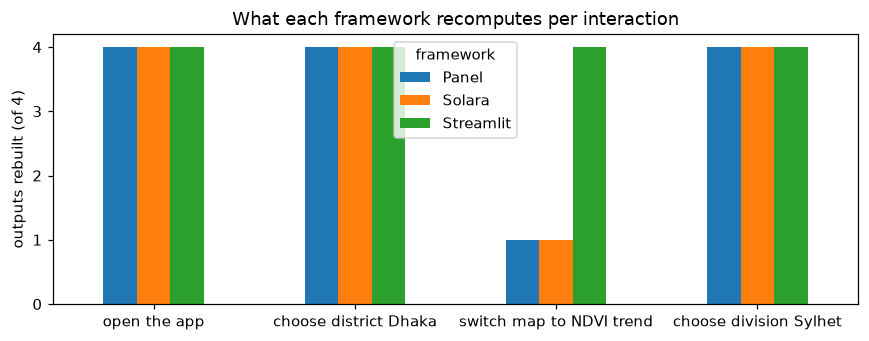

In [12]:
# Compare frameworks: timing, loader calls, and how many outputs rebuild per interaction
compare = pd.DataFrame(counts).T.fillna(0)
order = ["load_districts", "load_ndvi", "district_card", "choropleth", "ndvi_figure", "seasonal_figure"]
compare = compare.reindex(columns=["ms"] + order, fill_value=0)
compare["outputs rebuilt"] = compare[["district_card", "choropleth", "ndvi_figure", "seasonal_figure"]].sum(axis=1)
compare.index.names = ["framework", "interaction"]
display(compare.astype({c: int for c in order + ["outputs rebuilt"]}).round(0))

# Bar chart of outputs rebuilt for each interaction step
fig, ax = plt.subplots(figsize=(8, 3.2))
pivot = compare["outputs rebuilt"].unstack(0).loc[[s for s, _ in steps]]
pivot.plot.bar(ax=ax, rot=0)
ax.set_ylabel("outputs rebuilt (of 4)"); ax.set_xlabel("")
ax.set_title("What each framework recomputes per interaction")
plt.tight_layout(); plt.show()

Streamlit rebuilt 4 outputs for every interaction. Panel and Solara rebuilt 4 when the district
changed and 1 when only the map variable changed. With a cheap app this hardly matters; with an
expensive map or chart it decides how responsive the app feels.

Streamlit's remedies are to cache the figure functions (`st.cache_data`, keyed by their arguments)
or to wrap independent parts in `@st.fragment`, which reruns only that part. The timings here come
from test harnesses that do different amounts of work (AppTest serialises the whole page), so
compare the counts rather than the milliseconds.

## Running the apps as servers

Each framework has its own server command:

| Framework | Command | Health check |
|---|---|---|
| Streamlit | `streamlit run apps/bd_streamlit.py --server.port 8501` | `/_stcore/health` |
| Panel | `panel serve apps/bd_panel.py --port 5006` | the app page |
| Solara | `solara run apps/bd_solara.py --port 8765 --production` | the app page |

We start all three, wait until they answer, and record start-up time and memory. Each server is a
separate process.

In [13]:
# Launch Streamlit, Panel, and Solara servers; record start-up time, memory, and first HTML size
# Helpers: free TCP port and process RSS including children
def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0)); return s.getsockname()[1]

def rss_mb(proc):
    p = psutil.Process(proc.pid)
    return sum(q.memory_info().rss for q in [p] + p.children(recursive=True)) / 1e6

# Start each framework server and wait until healthy
ports = {name: free_port() for name in ["Streamlit", "Panel", "Solara"]}
commands = {
    "Streamlit": ([sys.executable, "-m", "streamlit", "run", "bd_streamlit.py", "--server.port", str(ports["Streamlit"]),
                   "--server.headless", "true", "--browser.gatherUsageStats", "false"], "/_stcore/health", "/"),
    "Panel": ([sys.executable, "-m", "panel", "serve", "bd_panel.py", "--port", str(ports["Panel"]), "--address", "127.0.0.1",
               "--allow-websocket-origin", f"127.0.0.1:{ports['Panel']}", "--allow-websocket-origin", f"localhost:{ports['Panel']}"],
              "/bd_panel", "/bd_panel"),
    "Solara": ([sys.executable, "-m", "solara", "run", "bd_solara.py", "--port", str(ports["Solara"]), "--host", "127.0.0.1",
                "--no-open", "--production"], "/", "/"),
}
servers, rows = {}, []
for name, (cmd, health, page) in commands.items():
    t0 = time.perf_counter()
    proc = subprocess.Popen(cmd, cwd=APPS, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    base = f"http://127.0.0.1:{ports[name]}"
    while time.perf_counter() - t0 < 120:
        try:
            if httpx.get(base + health, timeout=5).status_code == 200:
                break
        except httpx.HTTPError:
            pass
        time.sleep(0.2)
    started = time.perf_counter() - t0
    idle = rss_mb(proc)
    r = httpx.get(base + page, timeout=60)
    servers[name] = (proc, base + page)
    rows.append({"framework": name, "start-up s": round(started, 1), "memory at start MB": round(idle),
                 "page status": r.status_code, "first HTML kB": round(len(r.content) / 1e3, 1)})
startup = pd.DataFrame(rows).set_index("framework")
startup

,start-up s,memory at start MB,page status,first HTML kB
framework,,,,
Streamlit,0.8,82,200,6.5
Panel,2.7,276,200,13.7
Solara,1.3,212,200,75.2


All three servers answered in under 3 s:

| Framework | Start-up | Memory before any user connects | First page |
|---|---|---|---|
| Streamlit | 0.8 s | 82 MB | 6.5 kB |
| Solara | 1.3 s | 212 MB | 75.2 kB |
| Panel | 2.7 s | 276 MB | 13.7 kB |

These are the costs before any user connects. Streamlit and Panel run the app script, and load
the cached data, when the first session opens; Solara imports the app module at start-up.

The first page is only a shell: the widgets, map and charts arrive over the WebSocket once the
browser connects.

The running apps, as a browser sees them (they are served by processes started from this notebook
and stop with it):

In [14]:
# Embed each running app in an IFrame
for name, (proc, url) in servers.items():
    print(name, url)
    display(IFrame(url, width="100%", height=560))

Streamlit http://127.0.0.1:50855/


Panel http://127.0.0.1:47829/bd_panel


Solara http://127.0.0.1:41431/


In [15]:
# Stop all three app servers
for name, (proc, url) in servers.items():
    proc.terminate(); proc.wait(timeout=20)
print("servers stopped")

servers stopped


Each open browser tab is a session with its own widget state on the server. Streamlit and Panel
run the app script for every new session but share cached data between sessions; Solara keeps one
set of reactive variables per session. A server's capacity therefore depends on memory per session
and on how much work each interaction triggers (Section 8). To size a deployment, load-test with a
browser-automation tool (Playwright) or a WebSocket-capable load tester before going live.

## Sharing and choosing

| Hosting option | Suits | Notes |
|---|---|---|
| **Streamlit Community Cloud** | Streamlit apps from a public GitHub repository | Free; apps sleep when unused; resource limits |
| **Hugging Face Spaces** | Streamlit, Panel, Solara (Docker) | Free CPU tier; public or private |
| **A virtual machine or container service** (AWS, Azure, GCP, Fly.io, Render) | Any of the three | Run the server command behind HTTPS; Notebook 08_10 builds the Docker image |
| **WebAssembly in the browser** | Panel (`panel convert`), Streamlit (stlite) | No server at all; Python runs in the visitor's browser via Pyodide; only pure-Python or Pyodide-built packages |
| **Inside Jupyter / JupyterHub** | Panel, Solara | The same code as a notebook dashboard |

**Choosing a framework**

| If you need | Choose |
|---|---|
| A demo or internal tool by this afternoon | Streamlit |
| Linked, interactive views of large data (millions of points, cross-filtering) | Panel with HoloViews / hvPlot / Datashader |
| A larger app with many pages, reusable components and precise control of updates | Solara |
| The same dashboard in a notebook and as a web app | Panel or Solara |
| An app maintained by data scientists without front-end experience | Any of them, if the logic stays in a tested module (Section 3) |

**For geospatial apps in particular:**

- prepare data in advance (Section 4);
- serve heavy layers as tiles or PMTiles (Notebook 08_05) rather than as GeoJSON inside the page;
- call an API (Notebook 08_06) for analysis that should be shared with other clients;
- cache per process, not per session, anything that does not depend on the user.

## Summary and exercises

**Key ideas**

- Streamlit reruns the whole script on every interaction; Panel and Solara rerun only what depends on
  the changed input. Caching (`st.cache_data`, `pn.cache`, `use_memo`) is how each avoids repeated work.
- Put data and figures in a plain module; the app is a thin layer that is easy to test and to port.
- Precompute what the app shows; an app should load kilobytes.
- Test apps headlessly: `AppTest` for Streamlit, widget values for Panel, `solara.render` for Solara.
- Each browser tab is a server-side session; memory and CPU per session decide how many users a
  server can hold.

**What we built and measured**

- One logic module (133 lines) and three thin apps: Streamlit (49 lines), Panel and Solara.
- App data prepared once, 288 kB, loading in 0.03 s instead of 3.1 s.
- NDVI peaks rose in 62 of 64 districts from 2001 to 2024; only two coastal districts in the
  south-west declined.
- Switching the map variable rebuilt 4 outputs in Streamlit and 1 in Panel and Solara.
- Start-up: Streamlit 0.8 s and 82 MB, Solara 1.3 s and 212 MB, Panel 2.7 s and 276 MB (before any session).

**Exercises**

1. Add `@st.cache_data` to wrappers around `bd.choropleth`, `bd.ndvi_figure` and
   `bd.seasonal_figure` in the Streamlit app, and repeat the counts of Section 5. What changes, and
   what does the cache cost in memory?
2. Add a "compare with" district selector to all three apps that overlays a second district on the
   NDVI chart. How many lines did each framework need?
3. Make the Panel app show the districts with `pn.pane.DataFrame` sorted by the map variable, linked
   to the district selector.
4. Replace the Folium map in the Solara app with `ipyleaflet` (or leafmap) and make a click on a
   district select it.
5. Convert the Panel app to WebAssembly with `panel convert apps/bd_panel.py --to pyodide-worker` and
   list which dependencies prevent it from running in the browser.

**References**

- Streamlit documentation. https://docs.streamlit.io
- Panel documentation (HoloViz). https://panel.holoviz.org
- Solara documentation. https://solara.dev
- streamlit-folium. https://github.com/randyzwitch/streamlit-folium
- Wu, Q. (2021). leafmap. *Journal of Open Source Software*, 6(63), 3414.